## 0. Install Dependencies

In [1]:
!pip install -q segmentation-models-pytorch iterative-stratification


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 4.1 MB/s eta 0:00:00


## 1. Setup

In [2]:
import sys
import re
import gc
import random
import importlib
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp

from sklearn.model_selection import train_test_split
from scipy.spatial.distance import directed_hausdorff

print("Python:", sys.version.split()[0])
print("Torch:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU Count:", torch.cuda.device_count())
    for i in range(torch.cuda.device_count()):
        print(f"GPU {i}: {torch.cuda.get_device_name(i)}")

Python: 3.12.12
Torch: 2.10.0+cu128
CUDA Available: True
GPU Count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


## 2. Configuration

In [3]:
from types import SimpleNamespace

cfg = {
    "seed": 42,
    "img_size": 384,
    "batch_size": 4,
    "num_workers": 0,
    "amp": True,
    "train_ratio": 0.8,
    "max_hausdorff_samples": 40,
    "use_tqdm": True,
    "verbose": True,
    "grad_clip": 1.0,
    "weight_decay": 1e-4,
    "stage1_epochs": 10,
    "stage2_epochs": 20,
    "stage1_lr": 1e-3,
    "stage2_encoder_lr": 1e-5,
    "stage2_decoder_lr": 1e-4,
}
cfg = SimpleNamespace(**cfg)


def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(cfg.seed)

torch.backends.cudnn.deterministic = False
torch.backends.cudnn.benchmark = True

# Ubah path ini sesuai lokasi dataset kamu.
DATASET_ROOT = Path("/kaggle/input/datasets/sultandaulay/merged-football-semantic-segmentation-dataset/Combined_Dataset")

IMAGES_DIR = DATASET_ROOT / "images"
MASKS_DIR = DATASET_ROOT / "masks"
CLASSES_CSV = DATASET_ROOT / "classes.csv"

OUTPUT_DIR = Path("./artifacts_semseg_deeplabv3plus_resnet50")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_DP = False  # DataParallel causes OOM; single T4 (16GB) is sufficient

print(f"Device: {DEVICE} | DataParallel: {USE_DP}")


def cleanup_cuda():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

Device: cuda | DataParallel: False


## 3. Data Indexing & Class Map

In [4]:
classes_df = pd.read_csv(CLASSES_CSV).sort_values("Index").reset_index(drop=True)
NUM_CLASSES = int(classes_df["Index"].max()) + 1


def parse_rgb(s):
    parts = [int(x.strip()) for x in str(s).split(",")]
    if len(parts) != 3:
        raise ValueError(f"Invalid RGB value: {s}")
    return tuple(parts)


class_colors = {int(r.Index): parse_rgb(r.Color_RGB) for r in classes_df.itertuples()}
class_names = {int(r.Index): str(r.Class) for r in classes_df.itertuples()}

CLASS_ID_TO_NAME = class_names
CLASS_ID_TO_COLOR = np.array([class_colors[i] for i in range(NUM_CLASSES)], dtype=np.uint8)


def normalize_stem(stem: str) -> str:
    return re.sub(r"\s+", " ", stem.strip()).lower()


def mask_to_class_ids(mask_path: Path) -> np.ndarray:
    mask_arr = np.array(Image.open(mask_path))

    if mask_arr.ndim == 2:
        mask_ids = mask_arr.astype(np.int64)
        if mask_ids.min() < 0 or mask_ids.max() >= NUM_CLASSES:
            raise ValueError(f"Mask index out of class range in {mask_path}")
        return mask_ids

    raise ValueError(f"Unsupported mask shape {mask_arr.shape} for {mask_path}")


image_exts = {".jpg", ".png"}
images = sorted([p for p in IMAGES_DIR.iterdir() if p.suffix.lower() in image_exts])
masks = sorted([p for p in MASKS_DIR.iterdir() if p.suffix.lower() in image_exts])

mask_map = {normalize_stem(p.stem): p for p in masks}
pairs = []
missing_masks = []

for img_path in images:
    key = normalize_stem(img_path.stem)
    mask_path = mask_map.get(key)
    if mask_path is None:
        missing_masks.append(img_path.name)
        continue

    sample_id = img_path.stem
    source = "ds1" if sample_id.lower().startswith("ds1") else ("ds2" if sample_id.lower().startswith("ds2") else "other")
    pairs.append(
        {
            "sample_id": sample_id,
            "source": source,
            "image_path": str(img_path),
            "mask_path": str(mask_path),
        }
    )

data_df = pd.DataFrame(pairs).sort_values("sample_id").reset_index(drop=True)

print("Total images:", len(images))
print("Total masks:", len(masks))
print("Paired samples:", len(data_df))
print("Missing masks:", len(missing_masks))
if missing_masks:
    print("Missing mask examples:", missing_masks[:5])

if len(data_df) == 0:
    raise RuntimeError("No valid image-mask pairs found.")

print("\nClass mapping:")
display(classes_df)
print("\nSource distribution:")
print(data_df["source"].value_counts(dropna=False))

Total images: 200
Total masks: 200
Paired samples: 200
Missing masks: 0

Class mapping:


,Index,Class,Color_RGB
0,0,Background,"0,0,0"
1,1,Team 1,"255,0,0"
2,2,Team 2,"0,0,255"
3,3,Goalkeeper 1,"255,255,0"
4,4,Goalkeeper 2,"0,255,255"
5,5,Field/Ground,"0,128,0"
6,6,Spectators,"128,128,128"
7,7,Football,"255,255,255"
8,8,Advertisement,"255,165,0"
9,9,Goal Bar,"255,0,255"



Source distribution:
source
ds1    100
ds2    100
Name: count, dtype: int64


## 4. EDA

EDA scan:   0%|          | 0/200 [00:00<?, ?it/s]

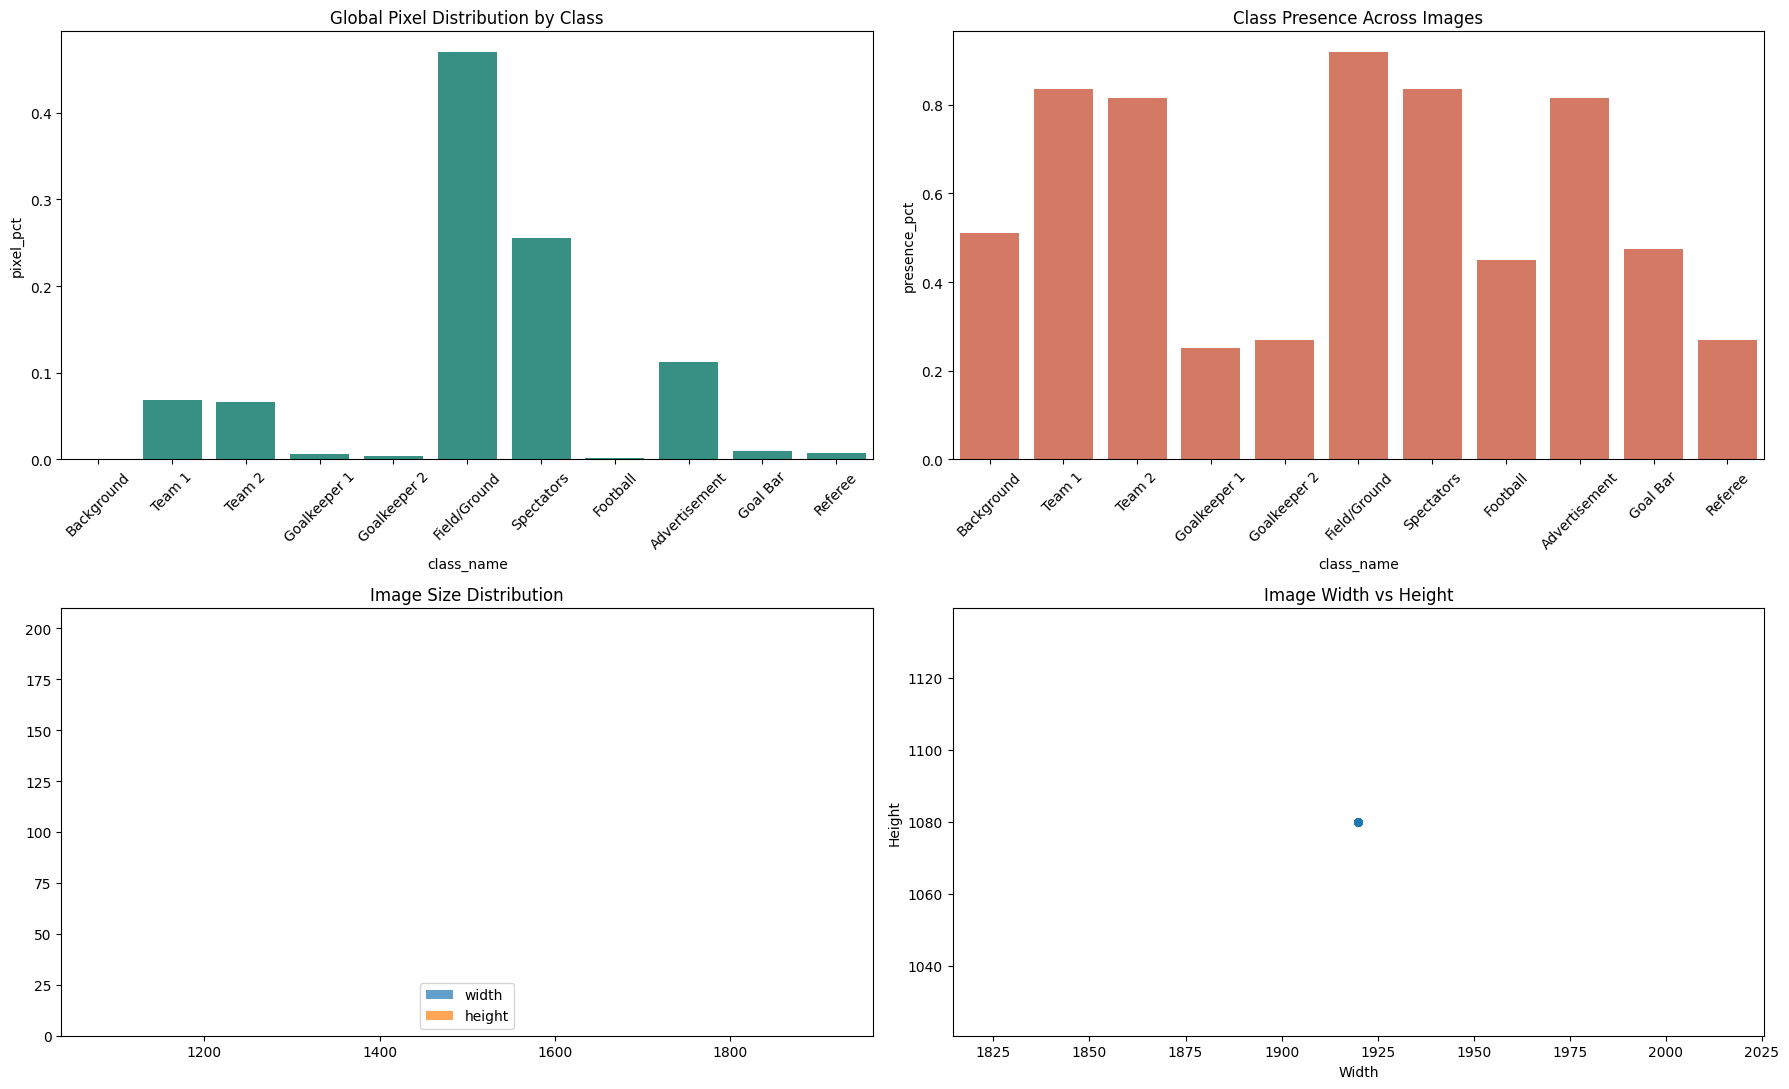

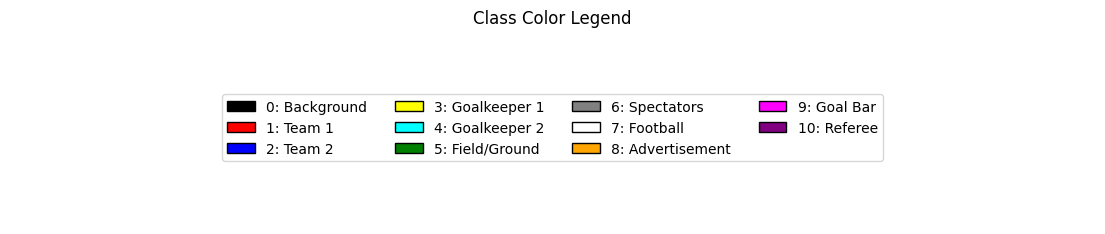

Insight (class paling jarang by presence):


,class_id,class_name,presence_pct
3,3,Goalkeeper 1,0.25
4,4,Goalkeeper 2,0.27
10,10,Referee,0.27


Insight (class paling kecil by pixel share):


,class_id,class_name,pixel_pct
0,0,Background,0.000034
7,7,Football,0.001462
4,4,Goalkeeper 2,0.003786


In [5]:
from matplotlib.patches import Patch

sample_class_pixels = {}
sample_class_presence = {}
image_sizes = []

class_pixel_counts = np.zeros(NUM_CLASSES, dtype=np.int64)
class_presence_counts = np.zeros(NUM_CLASSES, dtype=np.int64)

for row in tqdm(data_df.itertuples(index=False), total=len(data_df), desc="EDA scan"):
    image_path = Path(row.image_path)
    mask_path = Path(row.mask_path)

    with Image.open(image_path) as img:
        image_sizes.append(img.size)

    mask_ids = mask_to_class_ids(mask_path)

    counts = np.bincount(mask_ids.reshape(-1), minlength=NUM_CLASSES).astype(np.int64)
    presence = (counts > 0).astype(np.int64)

    sample_class_pixels[row.sample_id] = counts
    sample_class_presence[row.sample_id] = presence

    class_pixel_counts += counts
    class_presence_counts += presence

pixel_pct = class_pixel_counts / (class_pixel_counts.sum() + 1e-8)
presence_pct = class_presence_counts / len(data_df)

img_w = np.array([x[0] for x in image_sizes])
img_h = np.array([x[1] for x in image_sizes])

eda_df = pd.DataFrame(
    {
        "class_id": list(range(NUM_CLASSES)),
        "class_name": [CLASS_ID_TO_NAME[i] for i in range(NUM_CLASSES)],
        "pixel_count": class_pixel_counts,
        "pixel_pct": pixel_pct,
        "presence_images": class_presence_counts,
        "presence_pct": presence_pct,
    }
)

fig, axes = plt.subplots(2, 2, figsize=(18, 11))

sns.barplot(data=eda_df, x="class_name", y="pixel_pct", ax=axes[0, 0], color="#2a9d8f")
axes[0, 0].set_title("Global Pixel Distribution by Class")
axes[0, 0].tick_params(axis="x", rotation=45)

sns.barplot(data=eda_df, x="class_name", y="presence_pct", ax=axes[0, 1], color="#e76f51")
axes[0, 1].set_title("Class Presence Across Images")
axes[0, 1].tick_params(axis="x", rotation=45)

axes[1, 0].hist(img_w, bins=20, alpha=0.7, label="width")
axes[1, 0].hist(img_h, bins=20, alpha=0.7, label="height")
axes[1, 0].set_title("Image Size Distribution")
axes[1, 0].legend()

axes[1, 1].scatter(img_w, img_h, alpha=0.6, s=25)
axes[1, 1].set_title("Image Width vs Height")
axes[1, 1].set_xlabel("Width")
axes[1, 1].set_ylabel("Height")

plt.tight_layout()
plt.show()

legend_handles = [
    Patch(facecolor=np.array(CLASS_ID_TO_COLOR[i]) / 255.0, edgecolor="black", label=f"{i}: {CLASS_ID_TO_NAME[i]}")
    for i in range(NUM_CLASSES)
]

plt.figure(figsize=(14, 2.5))
plt.axis("off")
plt.legend(handles=legend_handles, ncol=4, loc="center")
plt.title("Class Color Legend")
plt.show()

rarest_by_presence = eda_df.sort_values("presence_pct", ascending=True).head(3)
rarest_by_pixels = eda_df.sort_values("pixel_pct", ascending=True).head(3)

print("Insight (class paling jarang by presence):")
display(rarest_by_presence[["class_id", "class_name", "presence_pct"]])
print("Insight (class paling kecil by pixel share):")
display(rarest_by_pixels[["class_id", "class_name", "pixel_pct"]])

## 5. Train/Val Split (80/20 Balanced)

In [6]:
sample_ids = data_df["sample_id"].tolist()
presence_matrix = np.stack([sample_class_presence[sid] for sid in sample_ids]).astype(np.int64)
pixel_matrix = np.stack([sample_class_pixels[sid] for sid in sample_ids]).astype(np.float64)


def make_balanced_split(df, presence_mat, pixel_mat, train_ratio=0.8, seed=42):
    idx = np.arange(len(df))
    test_size = 1.0 - train_ratio

    try:
        iter_mod = importlib.import_module("iterstrat.ml_stratifiers")
        splitter_cls = getattr(iter_mod, "MultilabelStratifiedShuffleSplit")
        splitter = splitter_cls(n_splits=1, test_size=test_size, random_state=seed)
        train_idx, val_idx = next(splitter.split(idx, presence_mat))
        method = "multilabel_iterstrat"
        return train_idx, val_idx, method
    except Exception:
        dominant = pixel_mat.argmax(axis=1)
        diversity = presence_mat.sum(axis=1)
        strata = pd.Series([f"{d}_{v}" for d, v in zip(dominant, diversity)])
        vc = strata.value_counts()
        strata = strata.map(lambda s: s if vc[s] >= 2 else "rare")

        for k in range(10):
            try:
                train_idx, val_idx = train_test_split(
                    idx,
                    test_size=test_size,
                    random_state=seed + k,
                    stratify=strata,
                    shuffle=True,
                )
                train_presence = presence_mat[train_idx].sum(axis=0)
                val_presence = presence_mat[val_idx].sum(axis=0)
                if (train_presence > 0).all() and (val_presence > 0).all():
                    method = "dominant_diversity_fallback"
                    return train_idx, val_idx, method
            except Exception:
                pass

        train_idx, val_idx = train_test_split(
            idx,
            test_size=test_size,
            random_state=seed,
            shuffle=True,
        )
        method = "random_fallback"
        return train_idx, val_idx, method


train_idx, val_idx, split_method = make_balanced_split(
    data_df, presence_matrix, pixel_matrix, train_ratio=cfg.train_ratio, seed=cfg.seed
)

train_df = data_df.iloc[train_idx].reset_index(drop=True)
val_df = data_df.iloc[val_idx].reset_index(drop=True)

train_pixels = pixel_matrix[train_idx].sum(axis=0)
val_pixels = pixel_matrix[val_idx].sum(axis=0)
val_pixel_ratio = val_pixels / (train_pixels + val_pixels + 1e-8)

train_presence = presence_matrix[train_idx].mean(axis=0)
val_presence = presence_matrix[val_idx].mean(axis=0)

split_stat_df = pd.DataFrame(
    {
        "class_id": range(NUM_CLASSES),
        "class_name": [CLASS_ID_TO_NAME[i] for i in range(NUM_CLASSES)],
        "val_pixel_ratio": val_pixel_ratio,
        "train_presence": train_presence,
        "val_presence": val_presence,
    }
)

split_csv = OUTPUT_DIR / "train_val_split.csv"
split_full_df = pd.concat(
    [
        train_df.assign(split="train"),
        val_df.assign(split="val"),
    ],
    axis=0,
).reset_index(drop=True)
split_full_df.to_csv(split_csv, index=False)

missing_train = split_stat_df.loc[split_stat_df["train_presence"] == 0, "class_name"].tolist()
missing_val = split_stat_df.loc[split_stat_df["val_presence"] == 0, "class_name"].tolist()

print("Split method:", split_method)
print(f"Train: {len(train_df)} | Val: {len(val_df)}")
print("Split saved to:", split_csv)
if missing_train:
    print("Warning - classes missing in train:", missing_train)
if missing_val:
    print("Warning - classes missing in val:", missing_val)
display(split_stat_df)

Split method: multilabel_iterstrat
Train: 159 | Val: 41
Split saved to: artifacts_semseg_deeplabv3plus_resnet50/train_val_split.csv


,class_id,class_name,val_pixel_ratio,train_presence,val_presence
0,0,Background,0.368984,0.515723,0.487805
1,1,Team 1,0.160936,0.842767,0.804878
2,2,Team 2,0.186118,0.811321,0.829268
3,3,Goalkeeper 1,0.183520,0.251572,0.243902
4,4,Goalkeeper 2,0.307140,0.270440,0.268293
5,5,Field/Ground,0.221186,0.905660,0.975610
6,6,Spectators,0.205945,0.836478,0.829268
7,7,Football,0.203753,0.427673,0.536585
8,8,Advertisement,0.167391,0.817610,0.804878
9,9,Goal Bar,0.173213,0.477987,0.463415


## 6. Dataset, Model, Loss, Metrics, Trainer

In [7]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)


def get_train_transform(use_aug=False):
    ops = [A.Resize(cfg.img_size, cfg.img_size)]
    if use_aug:
        ops += [
            A.HorizontalFlip(p=0.5),
            A.ShiftScaleRotate(
                shift_limit=0.05,
                scale_limit=0.10,
                rotate_limit=10,
                border_mode=0,
                p=0.5,
            ),
            A.RandomCrop(int(cfg.img_size * 0.75), int(cfg.img_size * 0.75), p=0.3),
            A.PadIfNeeded(cfg.img_size, cfg.img_size, border_mode=0, p=1.0),
            A.RandomBrightnessContrast(
                brightness_limit=0.2,
                contrast_limit=0.2,
                p=0.4,
            ),
            A.HueSaturationValue(
                hue_shift_limit=10,
                sat_shift_limit=20,
                val_shift_limit=20,
                p=0.3,
            ),
            A.GaussianBlur(blur_limit=3, p=0.2),
            A.ImageCompression(quality_range=(75, 100), p=0.2),
        ]
    ops += [
        A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ToTensorV2(),
    ]
    return A.Compose(ops)


def get_valid_transform():
    return A.Compose([
        A.Resize(cfg.img_size, cfg.img_size),
        A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        ToTensorV2(),
    ])


class SegDataset(Dataset):
    def __init__(self, frame, transform=None):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        image = np.array(Image.open(row["image_path"]).convert("RGB"))
        mask = mask_to_class_ids(Path(row["mask_path"]))

        if self.transform is not None:
            out = self.transform(image=image, mask=mask)
            image = out["image"]
            mask = out["mask"]

        if not torch.is_tensor(image):
            image = torch.from_numpy(image.transpose(2, 0, 1))
        image = image.float()

        if not torch.is_tensor(mask):
            mask = torch.from_numpy(mask)
        mask = mask.long()

        return {
            "image": image,
            "mask": mask,
            "sample_id": row["sample_id"],
            "image_path": row["image_path"],
        }


def make_loaders(train_frame, val_frame, use_aug=False, batch_size=None, shuffle_train=True):
    bs = cfg.batch_size if batch_size is None else batch_size

    train_ds = SegDataset(train_frame, transform=get_train_transform(use_aug=use_aug))
    val_ds = SegDataset(val_frame, transform=get_valid_transform())

    persistent = cfg.num_workers > 0

    train_loader = DataLoader(
        train_ds,
        batch_size=bs,
        shuffle=shuffle_train,
        num_workers=cfg.num_workers,
        pin_memory=False,
        drop_last=False,
        persistent_workers=persistent,
    )
    val_loader = DataLoader(
        val_ds,
        batch_size=bs,
        shuffle=False,
        num_workers=cfg.num_workers,
        pin_memory=False,
        drop_last=False,
        persistent_workers=persistent,
    )
    return train_loader, val_loader


def build_model(num_classes=NUM_CLASSES):
    model = smp.DeepLabV3Plus(
        encoder_name="resnet50",
        encoder_weights="imagenet",
        in_channels=3,
        classes=num_classes,
        activation=None,
    )
    if USE_DP:
        model = nn.DataParallel(model)
    return model.to(DEVICE)


def get_core_model(model):
    return model.module if isinstance(model, nn.DataParallel) else model


def set_encoder_trainable(model, trainable):
    core = get_core_model(model)
    for p in core.encoder.parameters():
        p.requires_grad = trainable


def make_dice_focal_criterion(dice_weight=0.6, focal_weight=0.4):
    dice_loss = smp.losses.DiceLoss(mode="multiclass", from_logits=True)
    focal_loss = smp.losses.FocalLoss(mode="multiclass")

    def _criterion(logits, targets):
        return dice_weight * dice_loss(logits, targets) + focal_weight * focal_loss(logits, targets)

    return _criterion


def update_confmat(confmat, preds, targets, num_classes):
    preds = preds.view(-1)
    targets = targets.view(-1)
    valid = (targets >= 0) & (targets < num_classes)
    idx = num_classes * targets[valid].to(torch.int64) + preds[valid].to(torch.int64)
    bins = torch.bincount(idx, minlength=num_classes * num_classes)
    confmat += bins.view(num_classes, num_classes)


def metrics_from_confmat(cm_np):
    eps = 1e-8
    tp = np.diag(cm_np).astype(np.float64)
    fp = cm_np.sum(axis=0) - tp
    fn = cm_np.sum(axis=1) - tp

    iou = tp / (tp + fp + fn + eps)
    dice = (2 * tp) / (2 * tp + fp + fn + eps)
    precision = tp / (tp + fp + eps)
    recall = tp / (tp + fn + eps)
    pixel_acc = tp.sum() / (cm_np.sum() + eps)

    return {
        "miou": float(np.nanmean(iou)),
        "dice": float(np.nanmean(dice)),
        "precision": float(np.nanmean(precision)),
        "recall": float(np.nanmean(recall)),
        "pixel_acc": float(pixel_acc),
        "iou_per_class": iou,
        "dice_per_class": dice,
        "precision_per_class": precision,
        "recall_per_class": recall,
    }


def composite_score(miou, dice):
    eps = 1e-8
    return float((2.0 * miou * dice) / (miou + dice + eps))


def binary_hausdorff(mask_a, mask_b):
    a_pts = np.argwhere(mask_a)
    b_pts = np.argwhere(mask_b)
    if len(a_pts) == 0 and len(b_pts) == 0:
        return 0.0
    if len(a_pts) == 0 or len(b_pts) == 0:
        return np.nan
    return float(max(directed_hausdorff(a_pts, b_pts)[0], directed_hausdorff(b_pts, a_pts)[0]))


def multiclass_hausdorff(pred_mask, true_mask, num_classes):
    vals = []
    for c in range(num_classes):
        hd = binary_hausdorff(pred_mask == c, true_mask == c)
        if not np.isnan(hd):
            vals.append(hd)
    return float(np.mean(vals)) if len(vals) > 0 else np.nan


def run_epoch(
    model,
    loader,
    criterion,
    optimizer=None,
    scaler=None,
    train=True,
    compute_hd=False,
    max_hd_samples=20,
    desc="",
):
    model.train() if train else model.eval()

    total_loss = 0.0
    seen = 0
    confmat = torch.zeros((NUM_CLASSES, NUM_CLASSES), dtype=torch.int64, device="cpu")
    hausdorff_vals = []

    phase = "train" if train else "val"
    iterator = tqdm(
        loader,
        leave=False,
        disable=not cfg.use_tqdm,
        desc=f"{desc} {phase} batches".strip(),
    )

    for batch in iterator:
        images = batch["image"].to(DEVICE, non_blocking=True)
        targets = batch["mask"].to(DEVICE, non_blocking=True)

        if train:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(train):
            with torch.amp.autocast(device_type=DEVICE.type, enabled=cfg.amp and DEVICE.type == "cuda"):
                logits = model(images)
                loss = criterion(logits, targets)

            if train:
                scaler.scale(loss).backward()
                if cfg.grad_clip > 0:
                    scaler.unscale_(optimizer)
                    nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
                scaler.step(optimizer)
                scaler.update()

        bs = images.size(0)
        total_loss += float(loss.item()) * bs
        seen += bs

        preds = torch.argmax(logits.detach(), dim=1)
        update_confmat(confmat, preds.cpu(), targets.detach().cpu(), NUM_CLASSES)

        if cfg.use_tqdm:
            iterator.set_postfix(loss=f"{loss.item():.4f}")

        if compute_hd and len(hausdorff_vals) < max_hd_samples:
            preds_np = preds.detach().cpu().numpy()
            targets_np = targets.detach().cpu().numpy()
            for i in range(preds_np.shape[0]):
                hd = multiclass_hausdorff(preds_np[i], targets_np[i], NUM_CLASSES)
                if not np.isnan(hd):
                    hausdorff_vals.append(hd)
                if len(hausdorff_vals) >= max_hd_samples:
                    break

    cm_np = confmat.numpy()
    metrics = metrics_from_confmat(cm_np)
    metrics["hausdorff"] = float(np.nanmean(hausdorff_vals)) if len(hausdorff_vals) > 0 else np.nan
    avg_loss = total_loss / max(seen, 1)

    return avg_loss, metrics, cm_np


def save_model_state(model):
    return model.module.state_dict() if isinstance(model, nn.DataParallel) else model.state_dict()


def train_model_staged(train_loader, val_loader, criterion, run_name):
    model = build_model(NUM_CLASSES)
    scaler = torch.amp.GradScaler(enabled=cfg.amp and DEVICE.type == "cuda")

    best_score = -1.0
    best_epoch = -1
    history = []
    ckpt_path = OUTPUT_DIR / f"{run_name}_best.pth"

    set_encoder_trainable(model, False)
    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=cfg.stage1_lr,
        weight_decay=cfg.weight_decay,
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=max(1, cfg.stage1_epochs),
    )

    for epoch in range(1, cfg.stage1_epochs + 1):
        train_loss, train_metrics, _ = run_epoch(
            model=model,
            loader=train_loader,
            criterion=criterion,
            optimizer=optimizer,
            scaler=scaler,
            train=True,
            compute_hd=False,
            desc=f"{run_name} s1e{epoch:02d}",
        )
        val_loss, val_metrics, _ = run_epoch(
            model=model,
            loader=val_loader,
            criterion=criterion,
            optimizer=None,
            scaler=None,
            train=False,
            compute_hd=False,
            desc=f"{run_name} s1e{epoch:02d}",
        )

        score = composite_score(val_metrics["miou"], val_metrics["dice"])
        scheduler.step()
        lr_now = float(optimizer.param_groups[0]["lr"])

        history.append(
            {
                "stage": "stage1",
                "stage_epoch": epoch,
                "epoch": epoch,
                "train_loss": train_loss,
                "val_loss": val_loss,
                "train_miou": train_metrics["miou"],
                "train_dice": train_metrics["dice"],
                "val_miou": val_metrics["miou"],
                "val_dice": val_metrics["dice"],
                "val_score": score,
                "lr": lr_now,
            }
        )

        if score > best_score:
            best_score = score
            best_epoch = epoch
            torch.save(
                {
                    "run_name": run_name,
                    "epoch": epoch,
                    "best_score": best_score,
                    "state_dict": save_model_state(model),
                    "history": history,
                },
                ckpt_path,
            )

        if cfg.verbose:
            print(
                f"[{run_name}][stage1] ep {epoch:02d}/{cfg.stage1_epochs} "
                f"val_mIoU={val_metrics['miou']:.4f} val_dice={val_metrics['dice']:.4f} "
                f"score={score:.4f} lr={lr_now:.2e}"
            )

    set_encoder_trainable(model, True)
    core = get_core_model(model)
    optimizer = torch.optim.AdamW(
        [
            {"params": core.encoder.parameters(), "lr": cfg.stage2_encoder_lr},
            {"params": core.decoder.parameters(), "lr": cfg.stage2_decoder_lr},
            {"params": core.segmentation_head.parameters(), "lr": cfg.stage2_decoder_lr},
        ],
        weight_decay=cfg.weight_decay,
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=max(1, cfg.stage2_epochs),
    )

    for epoch in range(1, cfg.stage2_epochs + 1):
        global_epoch = cfg.stage1_epochs + epoch

        train_loss, train_metrics, _ = run_epoch(
            model=model,
            loader=train_loader,
            criterion=criterion,
            optimizer=optimizer,
            scaler=scaler,
            train=True,
            compute_hd=False,
            desc=f"{run_name} s2e{epoch:02d}",
        )
        val_loss, val_metrics, _ = run_epoch(
            model=model,
            loader=val_loader,
            criterion=criterion,
            optimizer=None,
            scaler=None,
            train=False,
            compute_hd=False,
            desc=f"{run_name} s2e{epoch:02d}",
        )

        score = composite_score(val_metrics["miou"], val_metrics["dice"])
        scheduler.step()
        lr_now = float(optimizer.param_groups[0]["lr"])

        history.append(
            {
                "stage": "stage2",
                "stage_epoch": epoch,
                "epoch": global_epoch,
                "train_loss": train_loss,
                "val_loss": val_loss,
                "train_miou": train_metrics["miou"],
                "train_dice": train_metrics["dice"],
                "val_miou": val_metrics["miou"],
                "val_dice": val_metrics["dice"],
                "val_score": score,
                "lr": lr_now,
            }
        )

        if score > best_score:
            best_score = score
            best_epoch = global_epoch
            torch.save(
                {
                    "run_name": run_name,
                    "epoch": global_epoch,
                    "best_score": best_score,
                    "state_dict": save_model_state(model),
                    "history": history,
                },
                ckpt_path,
            )

        if cfg.verbose:
            print(
                f"[{run_name}][stage2] ep {epoch:02d}/{cfg.stage2_epochs} "
                f"val_mIoU={val_metrics['miou']:.4f} val_dice={val_metrics['dice']:.4f} "
                f"score={score:.4f} lr={lr_now:.2e}"
            )

    history_df = pd.DataFrame(history)

    del model, optimizer, scheduler, scaler
    cleanup_cuda()

    return {
        "run_name": run_name,
        "checkpoint": str(ckpt_path),
        "best_score": float(best_score),
        "best_epoch": int(best_epoch),
        "history": history_df,
    }


def load_model_from_checkpoint(checkpoint_path):
    model = build_model(NUM_CLASSES)
    ckpt = torch.load(checkpoint_path, map_location=DEVICE, weights_only=False)
    state = ckpt["state_dict"]
    if isinstance(model, nn.DataParallel):
        model.module.load_state_dict(state)
    else:
        model.load_state_dict(state)
    model.eval()
    return model, ckpt

In [8]:
def train_with_failfast(train_frame, val_frame, use_aug, criterion, run_name, batch_size=None):
    bs = cfg.batch_size if batch_size is None else batch_size

    train_loader = None
    val_loader = None
    try:
        train_loader, val_loader = make_loaders(
            train_frame,
            val_frame,
            use_aug=use_aug,
            batch_size=bs,
            shuffle_train=True,
        )
        result = train_model_staged(
            train_loader=train_loader,
            val_loader=val_loader,
            criterion=criterion,
            run_name=run_name,
        )
        result["used_batch_size"] = bs
        return result
    except RuntimeError as e:
        if "out of memory" in str(e).lower():
            raise RuntimeError(
                f"[{run_name}] OOM pada batch_size={bs}. Mode fail-fast aktif, training dihentikan."
            ) from e
        raise
    finally:
        del train_loader, val_loader
        cleanup_cuda()

## 7. Scenario 1: No Aug + Cross Entropy

In [9]:
scenario1_result = train_with_failfast(
    train_frame=train_df,
    val_frame=val_df,
    use_aug=False,
    criterion=nn.CrossEntropyLoss(),
    run_name="scenario1_noaug_ce",
)

print("Scenario 1 best score:", scenario1_result["best_score"])
print("Scenario 1 checkpoint:", scenario1_result["checkpoint"])
print("Scenario 1 used batch size:", scenario1_result["used_batch_size"])
display(scenario1_result["history"].tail())
cleanup_cuda()

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

scenario1_noaug_ce s1e01 train batches:   0%|          | 0/40 [00:00<?, ?it/s]

scenario1_noaug_ce s1e01 val batches:   0%|          | 0/11 [00:00<?, ?it/s]

[scenario1_noaug_ce][stage1] ep 01/10 val_mIoU=0.3187 val_dice=0.3821 score=0.3475 lr=9.76e-04


...

[scenario1_noaug_ce][stage2] ep 19/20 val_mIoU=0.6081 val_dice=0.7047 score=0.6529 lr=6.16e-08


scenario1_noaug_ce s2e20 train batches:   0%|          | 0/40 [00:00<?, ?it/s]

scenario1_noaug_ce s2e20 val batches:   0%|          | 0/11 [00:00<?, ?it/s]

[scenario1_noaug_ce][stage2] ep 20/20 val_mIoU=0.6090 val_dice=0.7053 score=0.6536 lr=0.00e+00
Scenario 1 best score: 0.6598390493050578
Scenario 1 checkpoint: artifacts_semseg_deeplabv3plus_resnet50/scenario1_noaug_ce_best.pth
Scenario 1 used batch size: 4


,stage,stage_epoch,epoch,train_loss,val_loss,train_miou,train_dice,val_miou,val_dice,val_score,lr
25,stage2,16,26,0.091730,0.160176,0.731097,0.804976,0.604568,0.701766,0.649551,9.549150e-07
26,stage2,17,27,0.091423,0.159972,0.731810,0.805519,0.608866,0.704969,0.653403,5.449674e-07
27,stage2,18,28,0.094424,0.154501,0.728651,0.802926,0.615450,0.711128,0.659839,2.447174e-07
28,stage2,19,29,0.094668,0.157577,0.730049,0.804074,0.608077,0.704750,0.652854,6.155830e-08
29,stage2,20,30,0.091846,0.155976,0.735872,0.808642,0.608994,0.705319,0.653627,0.000000e+00


## 8. Scenario 2: Aug + Cross Entropy

In [10]:
scenario2_result = train_with_failfast(
    train_frame=train_df,
    val_frame=val_df,
    use_aug=True,
    criterion=nn.CrossEntropyLoss(),
    run_name="scenario2_aug_ce",
)

print("Scenario 2 best score:", scenario2_result["best_score"])
print("Scenario 2 checkpoint:", scenario2_result["checkpoint"])
print("Scenario 2 used batch size:", scenario2_result["used_batch_size"])
display(scenario2_result["history"].tail())
cleanup_cuda()

scenario2_aug_ce s1e01 train batches:   0%|          | 0/40 [00:00<?, ?it/s]

scenario2_aug_ce s1e01 val batches:   0%|          | 0/11 [00:00<?, ?it/s]

[scenario2_aug_ce][stage1] ep 01/10 val_mIoU=0.2931 val_dice=0.3484 score=0.3184 lr=9.76e-04


scenario2_aug_ce s1e02 train batches:   0%|          | 0/40 [00:00<?, ?it/s]

scenario2_aug_ce s1e02 val batches:   0%|          | 0/11 [00:00<?, ?it/s]

...

[scenario2_aug_ce][stage2] ep 19/20 val_mIoU=0.6096 val_dice=0.7044 score=0.6536 lr=6.16e-08


scenario2_aug_ce s2e20 train batches:   0%|          | 0/40 [00:00<?, ?it/s]

scenario2_aug_ce s2e20 val batches:   0%|          | 0/11 [00:00<?, ?it/s]

[scenario2_aug_ce][stage2] ep 20/20 val_mIoU=0.6090 val_dice=0.7039 score=0.6530 lr=0.00e+00
Scenario 2 best score: 0.6535633138997887
Scenario 2 checkpoint: artifacts_semseg_deeplabv3plus_resnet50/scenario2_aug_ce_best.pth
Scenario 2 used batch size: 4


,stage,stage_epoch,epoch,train_loss,val_loss,train_miou,train_dice,val_miou,val_dice,val_score,lr
25,stage2,16,26,0.150254,0.161256,0.713467,0.812656,0.608340,0.703739,0.652571,9.549150e-07
26,stage2,17,27,0.154505,0.159871,0.716148,0.817396,0.609162,0.704065,0.653184,5.449674e-07
27,stage2,18,28,0.153376,0.159575,0.714820,0.816304,0.608106,0.702918,0.652083,2.447174e-07
28,stage2,19,29,0.154600,0.158419,0.708299,0.808979,0.609580,0.704388,0.653563,6.155830e-08
29,stage2,20,30,0.151255,0.159840,0.713010,0.812441,0.608983,0.703889,0.653005,0.000000e+00


## 9. Scenario Selection for Scenario 3

In [11]:
score_s1 = float(scenario1_result["best_score"])
score_s2 = float(scenario2_result["best_score"])

if score_s2 > score_s1:
    selected_use_aug = True
    selected_source = "scenario2_aug_ce"
else:
    selected_use_aug = False
    selected_source = "scenario1_noaug_ce"

print(f"Scenario 1 score: {score_s1:.6f}")
print(f"Scenario 2 score: {score_s2:.6f}")
print(f"Selected branch for Scenario 3: {selected_source} | use_aug={selected_use_aug}")

Scenario 1 score: 0.659839
Scenario 2 score: 0.653563
Selected branch for Scenario 3: scenario1_noaug_ce | use_aug=False


## 10. Scenario 3: Selected Aug/No-Aug + Dice + Focal

In [12]:
scenario3_result = train_with_failfast(
    train_frame=train_df,
    val_frame=val_df,
    use_aug=selected_use_aug,
    criterion=make_dice_focal_criterion(),
    run_name=f"scenario3_{'aug' if selected_use_aug else 'noaug'}_dicefocal",
)

print("Scenario 3 best score:", scenario3_result["best_score"])
print("Scenario 3 checkpoint:", scenario3_result["checkpoint"])
print("Scenario 3 used batch size:", scenario3_result["used_batch_size"])
display(scenario3_result["history"].tail())
cleanup_cuda()

scenario3_noaug_dicefocal s1e01 train batches:   0%|          | 0/40 [00:00<?, ?it/s]

scenario3_noaug_dicefocal s1e01 val batches:   0%|          | 0/11 [00:00<?, ?it/s]

[scenario3_noaug_dicefocal][stage1] ep 01/10 val_mIoU=0.3415 val_dice=0.4094 score=0.3724 lr=9.76e-04


scenario3_noaug_dicefocal s1e02 train batches:   0%|          | 0/40 [00:00<?, ?it/s]

scenario3_noaug_dicefocal s1e02 val batches:   0%|          | 0/11 [00:00<?, ?it/s]

...

[scenario3_noaug_dicefocal][stage2] ep 19/20 val_mIoU=0.6204 val_dice=0.7158 score=0.6647 lr=6.16e-08


scenario3_noaug_dicefocal s2e20 train batches:   0%|          | 0/40 [00:00<?, ?it/s]

scenario3_noaug_dicefocal s2e20 val batches:   0%|          | 0/11 [00:00<?, ?it/s]

[scenario3_noaug_dicefocal][stage2] ep 20/20 val_mIoU=0.6203 val_dice=0.7155 score=0.6645 lr=0.00e+00
Scenario 3 best score: 0.6760077562480122
Scenario 3 checkpoint: artifacts_semseg_deeplabv3plus_resnet50/scenario3_noaug_dicefocal_best.pth
Scenario 3 used batch size: 4


,stage,stage_epoch,epoch,train_loss,val_loss,train_miou,train_dice,val_miou,val_dice,val_score,lr
25,stage2,16,26,0.134331,0.222776,0.753925,0.822016,0.620370,0.714964,0.664317,9.549150e-07
26,stage2,17,27,0.126165,0.220925,0.761825,0.826814,0.622456,0.717318,0.666529,5.449674e-07
27,stage2,18,28,0.128293,0.220987,0.758350,0.824881,0.624148,0.718565,0.668037,2.447174e-07
28,stage2,19,29,0.128905,0.221631,0.759388,0.825193,0.620434,0.715776,0.664704,6.155830e-08
29,stage2,20,30,0.129970,0.222202,0.762136,0.827216,0.620293,0.715497,0.664503,0.000000e+00


## 11. Final Evaluation & Visualization

final-eval val batches:   0%|          | 0/11 [00:00<?, ?it/s]

Final validation metrics:


,mIoU,Dice,Pixel Accuracy,Precision,Recall,Hausdorff Distance,Composite Score,Val Loss
0,0.632115,0.726451,0.947219,0.80129,0.695931,32.963723,0.676008,0.215335


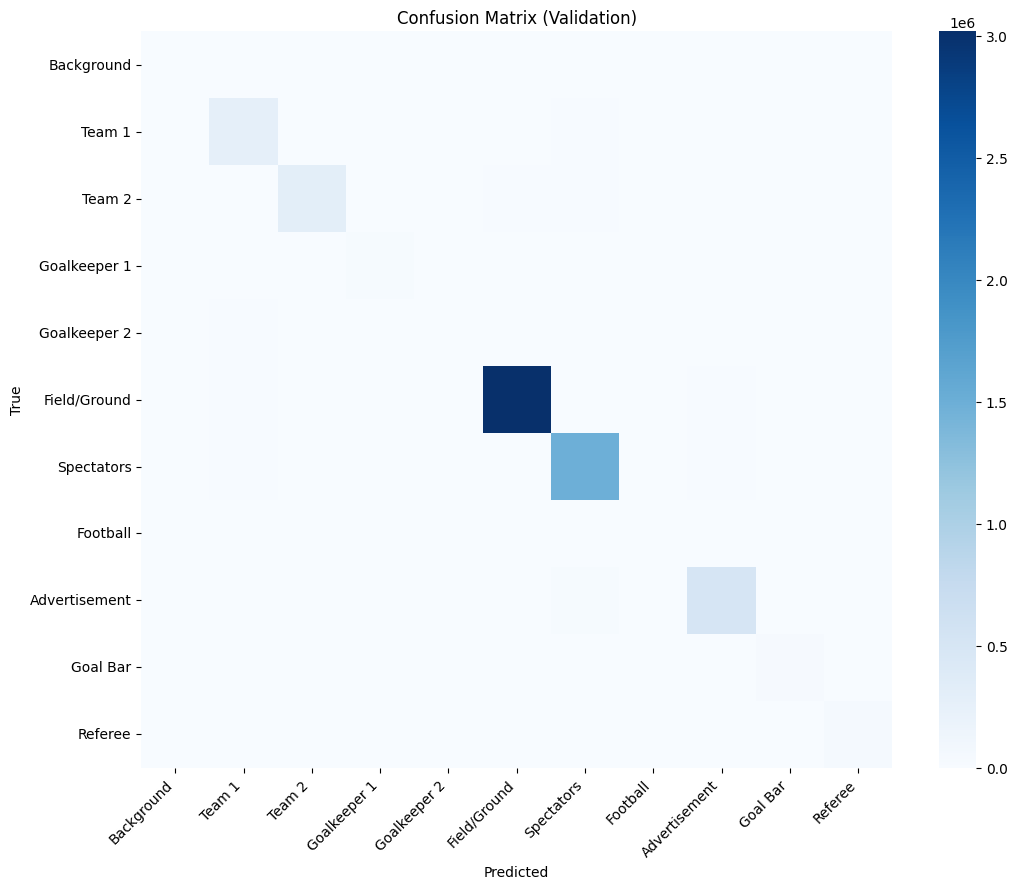

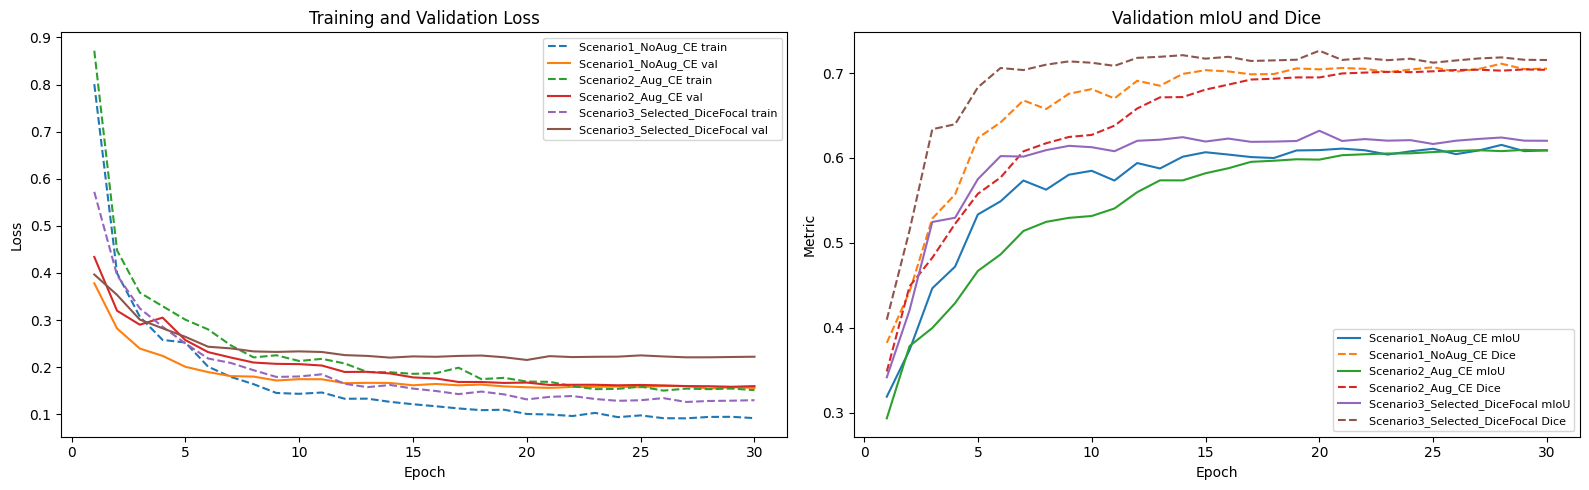

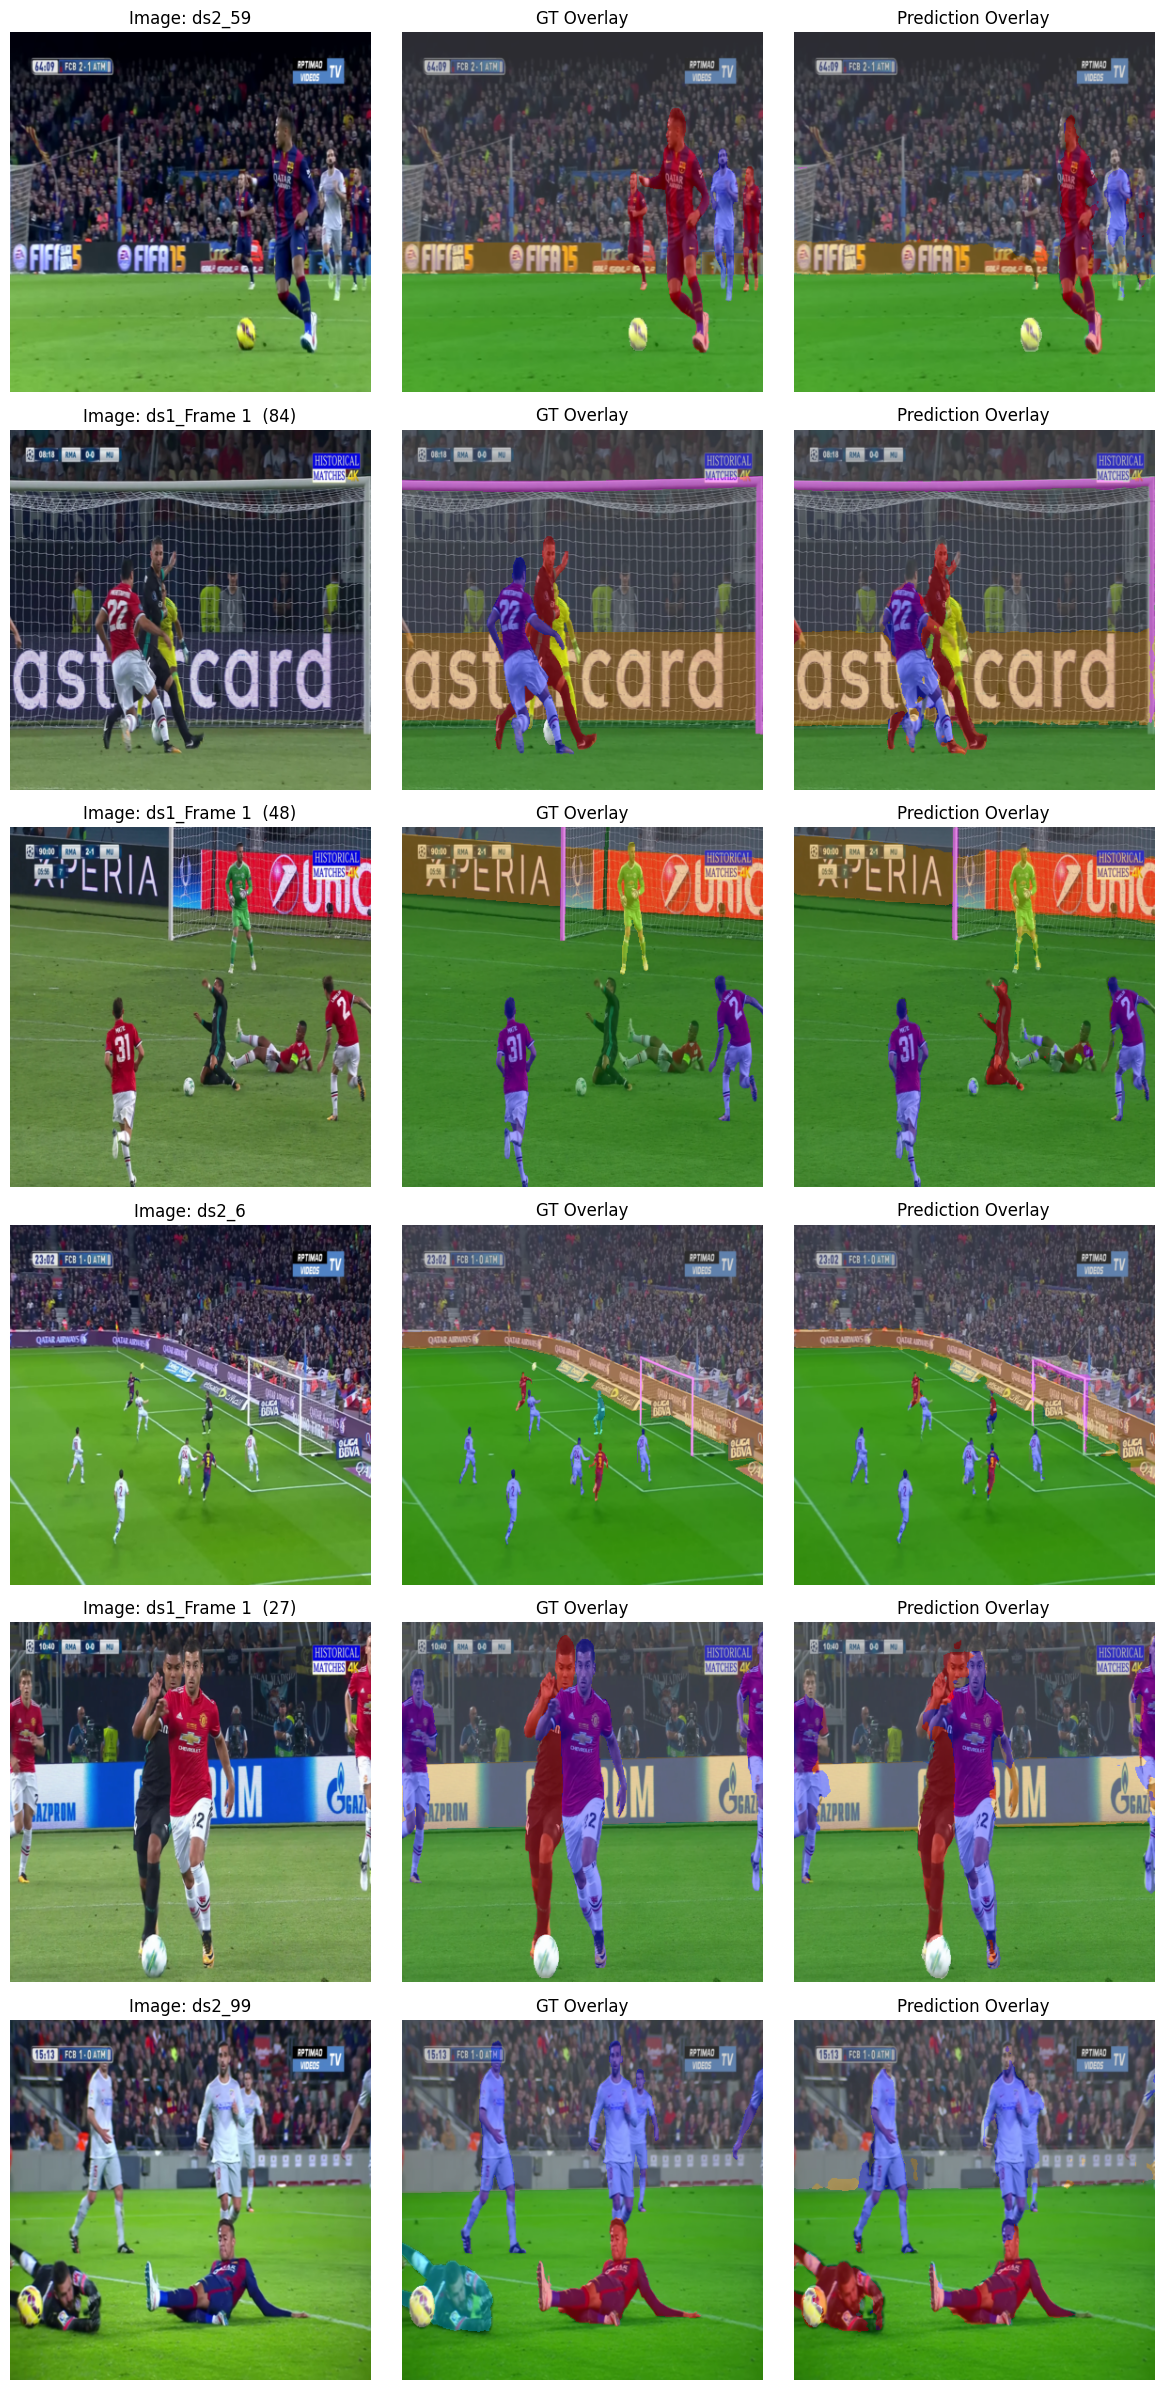

Saved artifacts:
- artifacts_semseg_deeplabv3plus_resnet50/final_metrics.csv
- artifacts_semseg_deeplabv3plus_resnet50/confusion_matrix.png
- artifacts_semseg_deeplabv3plus_resnet50/training_curves.png
- artifacts_semseg_deeplabv3plus_resnet50/prediction_samples.png
- artifacts_semseg_deeplabv3plus_resnet50/per_class_metrics.csv


,class_id,class_name,IoU,Dice,Precision,Recall
0,0,Background,0.000000,0.000000,0.000000,0.000000
1,1,Team 1,0.671432,0.803421,0.772040,0.837461
2,2,Team 2,0.765092,0.866915,0.881023,0.853251
3,3,Goalkeeper 1,0.674336,0.805497,0.870812,0.749296
4,4,Goalkeeper 2,0.197016,0.329179,0.842389,0.204557
5,5,Field/Ground,0.971907,0.985753,0.986333,0.985174
6,6,Spectators,0.916468,0.956413,0.950380,0.962524
7,7,Football,0.526920,0.690173,0.903623,0.558295
8,8,Advertisement,0.831813,0.908186,0.899936,0.916588
9,9,Goal Bar,0.722712,0.839040,0.859062,0.819930


In [13]:
eval_loader = DataLoader(
    SegDataset(val_df, transform=get_valid_transform()),
    batch_size=cfg.batch_size,
    shuffle=False,
    num_workers=cfg.num_workers,
    pin_memory=False,
    persistent_workers=(cfg.num_workers > 0),
)

final_model, final_ckpt = load_model_from_checkpoint(scenario3_result["checkpoint"])

final_val_loss, final_val_metrics, final_cm = run_epoch(
    model=final_model,
    loader=eval_loader,
    criterion=make_dice_focal_criterion(),
    optimizer=None,
    scaler=None,
    train=False,
    compute_hd=True,
    max_hd_samples=cfg.max_hausdorff_samples,
    desc="final-eval",
)

final_score = composite_score(final_val_metrics["miou"], final_val_metrics["dice"])

metrics_table = pd.DataFrame(
    [
        {
            "mIoU": final_val_metrics["miou"],
            "Dice": final_val_metrics["dice"],
            "Pixel Accuracy": final_val_metrics["pixel_acc"],
            "Precision": final_val_metrics["precision"],
            "Recall": final_val_metrics["recall"],
            "Hausdorff Distance": final_val_metrics["hausdorff"],
            "Composite Score": final_score,
            "Val Loss": final_val_loss,
        }
    ]
)
print("Final validation metrics:")
display(metrics_table)

metrics_csv_path = OUTPUT_DIR / "final_metrics.csv"
metrics_table.to_csv(metrics_csv_path, index=False)

cm_fig_path = OUTPUT_DIR / "confusion_matrix.png"
plt.figure(figsize=(11, 9))
sns.heatmap(
    final_cm,
    cmap="Blues",
    xticklabels=[CLASS_ID_TO_NAME[i] for i in range(NUM_CLASSES)],
    yticklabels=[CLASS_ID_TO_NAME[i] for i in range(NUM_CLASSES)],
)
plt.title("Confusion Matrix (Validation)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(cm_fig_path, dpi=180)
plt.show()

histories = {
    "Scenario1_NoAug_CE": scenario1_result["history"],
    "Scenario2_Aug_CE": scenario2_result["history"],
    "Scenario3_Selected_DiceFocal": scenario3_result["history"],
}

train_curve_path = OUTPUT_DIR / "training_curves.png"
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for name, h in histories.items():
    axes[0].plot(h["epoch"], h["train_loss"], linestyle="--", label=f"{name} train")
    axes[0].plot(h["epoch"], h["val_loss"], label=f"{name} val")

axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend(fontsize=8)

for name, h in histories.items():
    axes[1].plot(h["epoch"], h["val_miou"], label=f"{name} mIoU")
    axes[1].plot(h["epoch"], h["val_dice"], linestyle="--", label=f"{name} Dice")

axes[1].set_title("Validation mIoU and Dice")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Metric")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(train_curve_path, dpi=180)
plt.show()


def colorize_mask(mask_ids):
    return CLASS_ID_TO_COLOR[mask_ids]


def overlay_mask(image_rgb, mask_ids, alpha=0.35):
    color_mask = colorize_mask(mask_ids)
    blended = (image_rgb.astype(np.float32) * (1 - alpha) + color_mask.astype(np.float32) * alpha)
    return blended.astype(np.uint8)


sample_rows = val_df.sample(n=min(6, len(val_df)), random_state=cfg.seed).reset_index(drop=True)
plot_path = OUTPUT_DIR / "prediction_samples.png"

fig, axes = plt.subplots(len(sample_rows), 3, figsize=(12, 4 * len(sample_rows)))
if len(sample_rows) == 1:
    axes = np.expand_dims(axes, axis=0)

for r in range(len(sample_rows)):
    row = sample_rows.iloc[r]
    img = np.array(Image.open(row["image_path"]).convert("RGB").resize((cfg.img_size, cfg.img_size), Image.Resampling.BILINEAR))

    gt_mask_raw = mask_to_class_ids(Path(row["mask_path"]))
    gt_mask = np.array(
        Image.fromarray(gt_mask_raw.astype(np.uint8)).resize((cfg.img_size, cfg.img_size), Image.Resampling.NEAREST),
        dtype=np.int64,
    )

    transformed = get_valid_transform()(image=img, mask=gt_mask)
    img_tensor = transformed["image"]
    if torch.is_tensor(img_tensor):
        x = img_tensor.unsqueeze(0).float().to(DEVICE)
    else:
        x = torch.from_numpy(img_tensor.transpose(2, 0, 1)).unsqueeze(0).float().to(DEVICE)

    with torch.no_grad():
        with torch.amp.autocast(device_type=DEVICE.type, enabled=cfg.amp and DEVICE.type == "cuda"):
            logits = final_model(x)
        pred_mask = torch.argmax(logits, dim=1).squeeze(0).cpu().numpy().astype(np.int64)

    gt_overlay = overlay_mask(img, gt_mask, alpha=0.35)
    pred_overlay = overlay_mask(img, pred_mask, alpha=0.35)

    axes[r, 0].imshow(img)
    axes[r, 0].set_title(f"Image: {row['sample_id']}")
    axes[r, 1].imshow(gt_overlay)
    axes[r, 1].set_title("GT Overlay")
    axes[r, 2].imshow(pred_overlay)
    axes[r, 2].set_title("Prediction Overlay")

    for c in range(3):
        axes[r, c].axis("off")

plt.tight_layout()
plt.savefig(plot_path, dpi=180)
plt.show()

per_class_df = pd.DataFrame(
    {
        "class_id": range(NUM_CLASSES),
        "class_name": [CLASS_ID_TO_NAME[i] for i in range(NUM_CLASSES)],
        "IoU": final_val_metrics["iou_per_class"],
        "Dice": final_val_metrics["dice_per_class"],
        "Precision": final_val_metrics["precision_per_class"],
        "Recall": final_val_metrics["recall_per_class"],
    }
)
per_class_path = OUTPUT_DIR / "per_class_metrics.csv"
per_class_df.to_csv(per_class_path, index=False)

print("Saved artifacts:")
print("-", metrics_csv_path)
print("-", cm_fig_path)
print("-", train_curve_path)
print("-", plot_path)
print("-", per_class_path)

display(per_class_df)

del final_model, eval_loader
cleanup_cuda()